In [6]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# ==========================================
# CELL 2: LOAD DATA
# ==========================================

from google.colab import files

uploaded = files.upload()

Saving latency_dataset_tokenfixed.csv to latency_dataset_tokenfixed.csv


In [8]:
# ==========================================
# CELL 3: READ AND INSPECT DATA
# ==========================================

import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset shape: (180, 21)

Column names:
['request_id', 'run_id', 'workload_type', 'arrival_offset_s', 'prompt_text', 'prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib', 'queue_wait_s', 'engine_latency_s', 'end_to_end_s', 'ttft_engine_s', 'actual_output_tokens', 'status', 'error', 'output_preview']

First 5 rows:


,request_id,run_id,workload_type,arrival_offset_s,prompt_text,prompt_tokens,max_output_tokens,arrival_rate_5s_rps,queue_depth_at_admission,active_requests_at_admission,...,gpu_utilization_pct,gpu_memory_used_mib,queue_wait_s,engine_latency_s,end_to_end_s,ttft_engine_s,actual_output_tokens,status,error,output_preview
0,steady_run_1_req_0000,steady_run_1,steady,0.0,Request reference steady_run_1_req_0000\nGive ...,49,32,5.000000,0,0,...,0.0,12325.0,0.000392,0.543495,0.543888,0.066728,32,completed,NaN,"I'm sorry, but I don't have enough context to ..."
1,steady_run_1_req_0001,steady_run_1,steady,0.6,Request reference steady_run_1_req_0001. The p...,273,32,3.331942,0,0,...,0.0,12325.0,0.000054,0.531638,0.531692,0.070079,32,completed,NaN,The system described involves managing large l...
2,steady_run_1_req_0002,steady_run_1,steady,1.2,Request reference steady_run_1_req_0002. Throu...,529,96,2.497807,0,0,...,82.0,12349.0,0.000038,1.604798,1.604836,0.137945,96,completed,NaN,"Throughput, tail latency, and goodput are cruc..."
3,steady_run_1_req_0003,steady_run_1,steady,1.8,Request reference steady_run_1_req_0003. An ad...,145,32,1.781315,1,0,...,100.0,12369.0,1.006136,0.517767,1.523902,0.056292,32,completed,NaN,An admission controller in an online inference...
4,steady_run_1_req_0004,steady_run_1,steady,2.4,Request reference steady_run_1_req_0004. Throu...,273,32,1.804389,1,0,...,100.0,12369.0,0.923957,0.544150,1.468107,0.084668,32,completed,NaN,"The throughput, tail latency, and goodput metr..."



Data types:
request_id                       object
run_id                           object
workload_type                    object
arrival_offset_s                float64
prompt_text                      object
prompt_tokens                     int64
max_output_tokens                 int64
arrival_rate_5s_rps             float64
queue_depth_at_admission          int64
active_requests_at_admission      int64
concurrency_limit                 int64
gpu_utilization_pct             float64
gpu_memory_used_mib             float64
queue_wait_s                    float64
engine_latency_s                float64
end_to_end_s                    float64
ttft_engine_s                   float64
actual_output_tokens              int64
status                           object
error                           float64
output_preview                   object
dtype: object


In [9]:
# Check the dataset currently loaded

print("Dataset shape:", df.shape)

print("\nColumn names:")
for col in df.columns:
    print("-", col)

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Dataset shape: (180, 21)

Column names:
- request_id
- run_id
- workload_type
- arrival_offset_s
- prompt_text
- prompt_tokens
- max_output_tokens
- arrival_rate_5s_rps
- queue_depth_at_admission
- active_requests_at_admission
- concurrency_limit
- gpu_utilization_pct
- gpu_memory_used_mib
- queue_wait_s
- engine_latency_s
- end_to_end_s
- ttft_engine_s
- actual_output_tokens
- status
- error
- output_preview

First 5 rows:


,request_id,run_id,workload_type,arrival_offset_s,prompt_text,prompt_tokens,max_output_tokens,arrival_rate_5s_rps,queue_depth_at_admission,active_requests_at_admission,...,gpu_utilization_pct,gpu_memory_used_mib,queue_wait_s,engine_latency_s,end_to_end_s,ttft_engine_s,actual_output_tokens,status,error,output_preview
0,steady_run_1_req_0000,steady_run_1,steady,0.0,Request reference steady_run_1_req_0000\nGive ...,49,32,5.000000,0,0,...,0.0,12325.0,0.000392,0.543495,0.543888,0.066728,32,completed,NaN,"I'm sorry, but I don't have enough context to ..."
1,steady_run_1_req_0001,steady_run_1,steady,0.6,Request reference steady_run_1_req_0001. The p...,273,32,3.331942,0,0,...,0.0,12325.0,0.000054,0.531638,0.531692,0.070079,32,completed,NaN,The system described involves managing large l...
2,steady_run_1_req_0002,steady_run_1,steady,1.2,Request reference steady_run_1_req_0002. Throu...,529,96,2.497807,0,0,...,82.0,12349.0,0.000038,1.604798,1.604836,0.137945,96,completed,NaN,"Throughput, tail latency, and goodput are cruc..."
3,steady_run_1_req_0003,steady_run_1,steady,1.8,Request reference steady_run_1_req_0003. An ad...,145,32,1.781315,1,0,...,100.0,12369.0,1.006136,0.517767,1.523902,0.056292,32,completed,NaN,An admission controller in an online inference...
4,steady_run_1_req_0004,steady_run_1,steady,2.4,Request reference steady_run_1_req_0004. Throu...,273,32,1.804389,1,0,...,100.0,12369.0,0.923957,0.544150,1.468107,0.084668,32,completed,NaN,"The throughput, tail latency, and goodput metr..."



Missing values:
request_id                        0
run_id                            0
workload_type                     0
arrival_offset_s                  0
prompt_text                       0
prompt_tokens                     0
max_output_tokens                 0
arrival_rate_5s_rps               0
queue_depth_at_admission          0
active_requests_at_admission      0
concurrency_limit                 0
gpu_utilization_pct               0
gpu_memory_used_mib               0
queue_wait_s                      0
engine_latency_s                  0
end_to_end_s                      0
ttft_engine_s                     0
actual_output_tokens              0
status                            0
error                           180
output_preview                    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                 

In [10]:
# ==========================================
# CELL 4: UNDERSTAND OUR LATENCY DATASET
# ==========================================

print("1. WORKLOAD DISTRIBUTION")
print(df["workload_type"].value_counts())

print("\n2. RUN DISTRIBUTION")
print(df["run_id"].value_counts())

print("\n3. REQUEST STATUS")
print(df["status"].value_counts())

print("\n4. LATENCY STATISTICS (SECONDS)")
display(
    df[[
        "engine_latency_s",
        "end_to_end_s",
        "ttft_engine_s",
        "queue_wait_s"
    ]].describe()
)

print("\n5. PROMPT AND OUTPUT TOKEN STATISTICS")
display(
    df[[
        "prompt_tokens",
        "max_output_tokens",
        "actual_output_tokens"
    ]].describe()
)

1. WORKLOAD DISTRIBUTION
workload_type
steady    60
mixed     60
bursty    60
Name: count, dtype: int64

2. RUN DISTRIBUTION
run_id
steady_run_1    20
steady_run_2    20
steady_run_3    20
mixed_run_1     20
mixed_run_2     20
mixed_run_3     20
bursty_run_1    20
bursty_run_2    20
bursty_run_3    20
Name: count, dtype: int64

3. REQUEST STATUS
status
completed    180
Name: count, dtype: int64

4. LATENCY STATISTICS (SECONDS)


,engine_latency_s,end_to_end_s,ttft_engine_s,queue_wait_s
count,180.000000,180.000000,180.000000,180.000000
mean,1.025790,2.567432,0.092854,1.541643
std,0.388046,2.320584,0.045740,2.344709
min,0.483391,0.500512,0.037563,0.000026
25%,0.618234,1.099603,0.054996,0.000038
50%,1.081033,1.566540,0.080695,0.183243
75%,1.252665,3.503400,0.133647,2.563440
max,1.825926,11.089349,0.230952,9.902347



5. PROMPT AND OUTPUT TOKEN STATISTICS


,prompt_tokens,max_output_tokens,actual_output_tokens
count,180.000000,180.000000,180.000000
mean,250.022222,63.822222,58.127778
std,178.175670,25.648495,23.166637
min,49.000000,32.000000,20.000000
25%,144.000000,32.000000,32.000000
50%,272.500000,64.000000,64.000000
75%,273.000000,96.000000,73.000000
max,529.000000,96.000000,96.000000


In [11]:
features = [
    "prompt_tokens",
    "max_output_tokens",
    "arrival_rate_5s_rps",
    "queue_depth_at_admission",
    "active_requests_at_admission",
    "concurrency_limit"
]

target = "engine_latency_s"

In [12]:
print("1. WORKLOAD DISTRIBUTION")
print(df["workload_type"].value_counts())

print("\n2. RUN DISTRIBUTION")
print(df["run_id"].value_counts())

print("\n3. REQUEST STATUS")
print(df["status"].value_counts())

print("\n4. LATENCY STATISTICS (SECONDS)")
display(df[[
    "engine_latency_s",
    "end_to_end_s",
    "ttft_engine_s",
    "queue_wait_s"
]].describe())

print("\n5. PROMPT AND OUTPUT TOKEN STATISTICS")
display(df[[
    "prompt_tokens",
    "max_output_tokens",
    "actual_output_tokens"
]].describe())

1. WORKLOAD DISTRIBUTION
workload_type
steady    60
mixed     60
bursty    60
Name: count, dtype: int64

2. RUN DISTRIBUTION
run_id
steady_run_1    20
steady_run_2    20
steady_run_3    20
mixed_run_1     20
mixed_run_2     20
mixed_run_3     20
bursty_run_1    20
bursty_run_2    20
bursty_run_3    20
Name: count, dtype: int64

3. REQUEST STATUS
status
completed    180
Name: count, dtype: int64

4. LATENCY STATISTICS (SECONDS)


,engine_latency_s,end_to_end_s,ttft_engine_s,queue_wait_s
count,180.000000,180.000000,180.000000,180.000000
mean,1.025790,2.567432,0.092854,1.541643
std,0.388046,2.320584,0.045740,2.344709
min,0.483391,0.500512,0.037563,0.000026
25%,0.618234,1.099603,0.054996,0.000038
50%,1.081033,1.566540,0.080695,0.183243
75%,1.252665,3.503400,0.133647,2.563440
max,1.825926,11.089349,0.230952,9.902347



5. PROMPT AND OUTPUT TOKEN STATISTICS


,prompt_tokens,max_output_tokens,actual_output_tokens
count,180.000000,180.000000,180.000000
mean,250.022222,63.822222,58.127778
std,178.175670,25.648495,23.166637
min,49.000000,32.000000,20.000000
25%,144.000000,32.000000,32.000000
50%,272.500000,64.000000,64.000000
75%,273.000000,96.000000,73.000000
max,529.000000,96.000000,96.000000


In [13]:
# Select information available at request admission time
feature_columns = [
    "prompt_tokens",
    "max_output_tokens",
    "arrival_rate_5s_rps",
    "queue_depth_at_admission",
    "active_requests_at_admission",
    "concurrency_limit",
    "workload_type"
]

target_column = "engine_latency_s"

# Create feature dataset
X = df[feature_columns].copy()
y = df[target_column].copy()

# Convert workload_type into numerical columns
X = pd.get_dummies(
    X,
    columns=["workload_type"],
    dtype=int
)

# Keep run 3 of each workload for testing
test_runs = [
    "steady_run_3",
    "mixed_run_3",
    "bursty_run_3"
]

train_mask = ~df["run_id"].isin(test_runs)
test_mask = df["run_id"].isin(test_runs)

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining requests:", len(X_train))
print("Testing requests:", len(X_test))

print("\nTraining runs:")
print(df.loc[train_mask, "run_id"].value_counts())

print("\nTesting runs:")
print(df.loc[test_mask, "run_id"].value_counts())

print("\nFinal feature columns:")
print(X.columns.tolist())

Training features shape: (120, 9)
Testing features shape: (60, 9)

Training requests: 120
Testing requests: 60

Training runs:
run_id
steady_run_1    20
steady_run_2    20
mixed_run_1     20
mixed_run_2     20
bursty_run_1    20
bursty_run_2    20
Name: count, dtype: int64

Testing runs:
run_id
steady_run_3    20
mixed_run_3     20
bursty_run_3    20
Name: count, dtype: int64

Final feature columns:
['prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'workload_type_bursty', 'workload_type_mixed', 'workload_type_steady']


In [14]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

# Generate predictions on unseen test data
y_pred = rf_model.predict(X_test)

print("\nFirst 10 actual latency values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted latency values:")
print(y_pred[:10])

Random Forest training completed successfully!

First 10 actual latency values:
[1.18193128 0.5944974  0.50048121 1.00374703 1.15975643 1.33982094
 1.2157359  0.6031839  0.63965484 0.53205505]

First 10 predicted latency values:
[1.13259367 0.57447288 0.51881621 1.0289952  1.41152142 1.41152142
 1.14399745 0.57028469 0.67389346 0.54069521]


In [15]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("RANDOM FOREST MODEL EVALUATION")
print("--------------------------------")
print(f"MAE  : {mae:.4f} seconds")
print(f"RMSE : {rmse:.4f} seconds")
print(f"R²   : {r2:.4f}")

RANDOM FOREST MODEL EVALUATION
--------------------------------
MAE  : 0.1351 seconds
RMSE : 0.1859 seconds
R²   : 0.7209


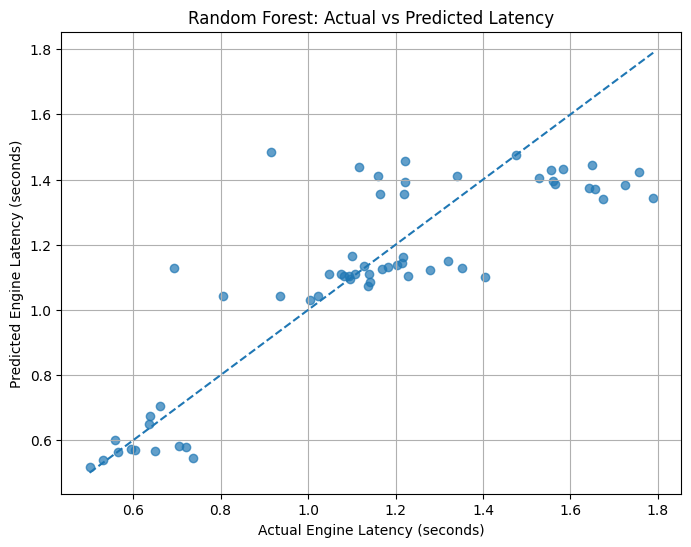

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Engine Latency (seconds)")
plt.ylabel("Predicted Engine Latency (seconds)")
plt.title("Random Forest: Actual vs Predicted Latency")

plt.grid(True)
plt.show()

FEATURE IMPORTANCE


,Feature,Importance
1,max_output_tokens,0.836778
2,arrival_rate_5s_rps,0.065876
3,queue_depth_at_admission,0.048998
0,prompt_tokens,0.025231
4,active_requests_at_admission,0.010450
7,workload_type_mixed,0.005279
6,workload_type_bursty,0.003241
8,workload_type_steady,0.002912
5,concurrency_limit,0.001235


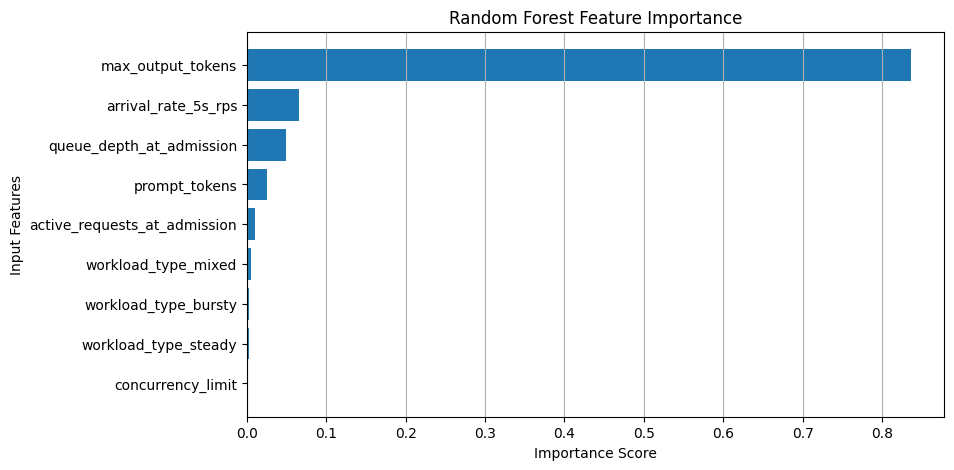

In [17]:
# Get feature importance from the trained model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
display(importance_df)

# Visualize feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Input Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.grid(axis="x")

plt.show()

In [18]:
import joblib

# Save the trained model
joblib.dump(
    rf_model,
    "camp_latency_predictor.joblib"
)

# Save the feature-column order
joblib.dump(
    X_train.columns.tolist(),
    "camp_feature_columns.joblib"
)

print("Predictor saved successfully!")
print("Files created:")
print("1. camp_latency_predictor.joblib")
print("2. camp_feature_columns.joblib")

Predictor saved successfully!
Files created:
1. camp_latency_predictor.joblib
2. camp_feature_columns.joblib


In [19]:
# Create a reusable latency prediction function

def predict_engine_latency(request):
    """
    Predict engine execution latency for one incoming request.

    request: dictionary containing admission-time features.
    Returns: predicted engine latency in seconds.
    """

    # Convert request dictionary into a DataFrame
    request_df = pd.DataFrame([request])

    # Convert workload category into numerical columns
    request_df = pd.get_dummies(
        request_df,
        columns=["workload_type"],
        dtype=int
    )

    # Ensure exactly the same columns and order as training
    request_df = request_df.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Predict latency
    predicted_latency = rf_model.predict(request_df)[0]

    return float(predicted_latency)


# Test the function using a real request from our dataset
sample_request = df.iloc[0]

request_data = {
    "prompt_tokens": sample_request["prompt_tokens"],
    "max_output_tokens": sample_request["max_output_tokens"],
    "arrival_rate_5s_rps": sample_request["arrival_rate_5s_rps"],
    "queue_depth_at_admission": sample_request["queue_depth_at_admission"],
    "active_requests_at_admission": sample_request["active_requests_at_admission"],
    "concurrency_limit": sample_request["concurrency_limit"],
    "workload_type": sample_request["workload_type"]
}

predicted_latency = predict_engine_latency(request_data)

print("SAMPLE REQUEST")
print("-----------------------------")
print("Workload:", request_data["workload_type"])
print("Prompt tokens:", request_data["prompt_tokens"])
print("Maximum output tokens:", request_data["max_output_tokens"])

print("\nPredicted engine latency:",
      round(predicted_latency, 4), "seconds")

print("Actual engine latency:",
      round(sample_request["engine_latency_s"], 4), "seconds")

SAMPLE REQUEST
-----------------------------
Workload: steady
Prompt tokens: 49
Maximum output tokens: 32

Predicted engine latency: 0.5252 seconds
Actual engine latency: 0.5435 seconds


In [20]:
# CAMP scheduler configuration

CAMP_CONFIG = {
    "max_concurrency": 4,
    "latency_threshold_s": 1.0
}

print("CAMP SCHEDULER CONFIGURATION")
print("----------------------------")
print("Maximum concurrency:",
      CAMP_CONFIG["max_concurrency"])

print("Predicted latency threshold:",
      CAMP_CONFIG["latency_threshold_s"], "seconds")

CAMP SCHEDULER CONFIGURATION
----------------------------
Maximum concurrency: 4
Predicted latency threshold: 1.0 seconds


In [21]:
def camp_admission_decision(request, active_requests):
    """
    CAMP admission-control decision.

    Returns the prediction and admission decision.
    """

    # Predict request latency
    predicted_latency = predict_engine_latency(request)

    # Check concurrency limit
    if active_requests >= CAMP_CONFIG["max_concurrency"]:
        decision = "DEFER"

    # Check predicted latency when system is busy
    elif (
        predicted_latency > CAMP_CONFIG["latency_threshold_s"]
        and active_requests > 0
    ):
        decision = "DEFER"

    else:
        decision = "ADMIT"

    return {
        "predicted_latency_s": round(predicted_latency, 4),
        "active_requests": active_requests,
        "decision": decision
    }


# Test CAMP using our sample request
print("CAMP ADMISSION TEST")
print("-------------------")

for active in [0, 1, 3, 4]:
    result = camp_admission_decision(
        request_data,
        active
    )

    print(
        f"Active requests: {active} | "
        f"Predicted latency: {result['predicted_latency_s']} s | "
        f"Decision: {result['decision']}"
    )

CAMP ADMISSION TEST
-------------------
Active requests: 0 | Predicted latency: 0.5252 s | Decision: ADMIT
Active requests: 1 | Predicted latency: 0.5252 s | Decision: ADMIT
Active requests: 3 | Predicted latency: 0.5252 s | Decision: ADMIT
Active requests: 4 | Predicted latency: 0.5252 s | Decision: DEFER


In [22]:
# Select one sample request from each workload
workload_samples = (
    df.groupby("workload_type", sort=True)
    .first()
    .reset_index()
)

print("CAMP WORKLOAD TEST")
print("=" * 60)

for _, sample in workload_samples.iterrows():

    request = {
        "prompt_tokens": sample["prompt_tokens"],
        "max_output_tokens": sample["max_output_tokens"],
        "arrival_rate_5s_rps": sample["arrival_rate_5s_rps"],
        "queue_depth_at_admission": sample["queue_depth_at_admission"],
        "active_requests_at_admission": sample["active_requests_at_admission"],
        "concurrency_limit": sample["concurrency_limit"],
        "workload_type": sample["workload_type"]
    }

    result = camp_admission_decision(
        request=request,
        active_requests=2
    )

    print(f"\nWorkload: {sample['workload_type']}")
    print(f"Predicted latency: {result['predicted_latency_s']} seconds")
    print(f"Admission decision: {result['decision']}")

CAMP WORKLOAD TEST

Workload: bursty
Predicted latency: 1.1283 seconds
Admission decision: DEFER

Workload: mixed
Predicted latency: 1.4174 seconds
Admission decision: DEFER

Workload: steady
Predicted latency: 0.5252 seconds
Admission decision: ADMIT


In [23]:
from google.colab import files
uploaded_benchmark = files.upload()

Saving benchmark_traces_tokenfixed.csv to benchmark_traces_tokenfixed (1).csv


In [24]:
import io
import pandas as pd

benchmark_filename = list(uploaded_benchmark.keys())[0]

benchmark_df = pd.read_csv(
    io.BytesIO(uploaded_benchmark[benchmark_filename])
)

print("Benchmark dataset shape:", benchmark_df.shape)

print("\nBenchmark columns:")
print(benchmark_df.columns.tolist())

print("\nFirst five benchmark requests:")
display(benchmark_df.head())

Benchmark dataset shape: (36, 6)

Benchmark columns:
['request_id', 'workload_type', 'arrival_offset_s', 'prompt_text', 'prompt_tokens', 'max_output_tokens']

First five benchmark requests:


,request_id,workload_type,arrival_offset_s,prompt_text,prompt_tokens,max_output_tokens
0,benchmark_steady_req_0000,steady,0.0,Request reference benchmark_steady_req_0000. A...,529,32
1,benchmark_steady_req_0001,steady,0.6,Request reference benchmark_steady_req_0001. T...,529,96
2,benchmark_steady_req_0002,steady,1.2,Request reference benchmark_steady_req_0002. A...,529,64
3,benchmark_steady_req_0003,steady,1.8,Request reference benchmark_steady_req_0003\nG...,49,96
4,benchmark_steady_req_0004,steady,2.4,Request reference benchmark_steady_req_0004\nG...,49,64


In [25]:
print("1. REQUESTS PER WORKLOAD")
print(benchmark_df["workload_type"].value_counts())

print("\n2. REQUEST ARRIVAL TIMES")
display(
    benchmark_df.groupby("workload_type")["arrival_offset_s"]
    .agg(["count", "min", "max", "mean"])
)

print("\n3. REQUEST SIZE STATISTICS")
display(
    benchmark_df.groupby("workload_type")[
        ["prompt_tokens", "max_output_tokens"]
    ].describe()
)

print("\n4. REQUEST ARRIVAL ORDER")
display(
    benchmark_df.sort_values("arrival_offset_s")[
        ["request_id", "workload_type",
         "arrival_offset_s", "prompt_tokens", "max_output_tokens"]
    ].head(15)
)

1. REQUESTS PER WORKLOAD
workload_type
steady    12
mixed     12
bursty    12
Name: count, dtype: int64

2. REQUEST ARRIVAL TIMES


,count,min,max,mean
workload_type,,,,
bursty,12,0.0,6.060000,2.355000
mixed,12,0.0,3.927952,1.890155
steady,12,0.0,6.600000,3.300000



3. REQUEST SIZE STATISTICS


prompt_tokens                                               \
                      count        mean         std   min     25%    50%   
workload_type                                                              
bursty                 12.0  350.333333  195.582735  49.0  145.00  401.0   
mixed                  12.0  179.166667  149.475953  48.0   48.00  145.0   
steady                 12.0  310.250000  204.670522  49.0  144.75  273.0   

                            max_output_tokens                              \
                 75%    max             count       mean        std   min   
workload_type                                                               
bursty         529.0  529.0              12.0  74.666667  24.911966  32.0   
mixed          273.0  529.0              12.0  72.000000  19.890610  32.0   
steady         529.0  529.0              12.0  66.666667  25.374767  32.0   

                                       
                25%   50%   75%   max  
workload_type                          
bursty         64.0  80.0  96.0  96.0  
mixed          64.0  64.0  96.0  96.0  
steady         56.0  64.0  96.0  96.0


4. REQUEST ARRIVAL ORDER


,request_id,workload_type,arrival_offset_s,prompt_tokens,max_output_tokens
0,benchmark_steady_req_0000,steady,0.000000,529,32
12,benchmark_mixed_req_0000,mixed,0.000000,48,64
24,benchmark_bursty_req_0000,bursty,0.000000,529,64
25,benchmark_bursty_req_0001,bursty,0.060000,529,96
26,benchmark_bursty_req_0002,bursty,0.120000,529,64
27,benchmark_bursty_req_0003,bursty,0.180000,145,32
28,benchmark_bursty_req_0004,bursty,0.240000,529,64
13,benchmark_mixed_req_0001,mixed,0.365892,272,64
1,benchmark_steady_req_0001,steady,0.600000,529,96
14,benchmark_mixed_req_0002,mixed,0.780717,48,64


In [26]:
# Sort all requests by arrival time
simulation_df = benchmark_df.sort_values(
    ["arrival_offset_s", "request_id"]
).copy()

# Calculate arrival rate using the previous 5-second window
arrival_rates = []

for arrival_time in simulation_df["arrival_offset_s"]:

    previous_arrivals = simulation_df[
        (simulation_df["arrival_offset_s"] <= arrival_time) &
        (simulation_df["arrival_offset_s"] > arrival_time - 5)
    ]

    rate = len(previous_arrivals) / 5.0
    arrival_rates.append(rate)

simulation_df["arrival_rate_5s_rps"] = arrival_rates

# Display prepared requests
print("PREPARED SIMULATION ARRIVAL STREAM")
print("----------------------------------")

display(
    simulation_df[
        [
            "request_id",
            "workload_type",
            "arrival_offset_s",
            "prompt_tokens",
            "max_output_tokens",
            "arrival_rate_5s_rps"
        ]
    ].head(15)
)

print("\nTotal requests:", len(simulation_df))
print("Total workload types:",
      simulation_df["workload_type"].nunique())

PREPARED SIMULATION ARRIVAL STREAM
----------------------------------


,request_id,workload_type,arrival_offset_s,prompt_tokens,max_output_tokens,arrival_rate_5s_rps
24,benchmark_bursty_req_0000,bursty,0.000000,529,64,0.6
12,benchmark_mixed_req_0000,mixed,0.000000,48,64,0.6
0,benchmark_steady_req_0000,steady,0.000000,529,32,0.6
25,benchmark_bursty_req_0001,bursty,0.060000,529,96,0.8
26,benchmark_bursty_req_0002,bursty,0.120000,529,64,1.0
27,benchmark_bursty_req_0003,bursty,0.180000,145,32,1.2
28,benchmark_bursty_req_0004,bursty,0.240000,529,64,1.4
13,benchmark_mixed_req_0001,mixed,0.365892,272,64,1.6
1,benchmark_steady_req_0001,steady,0.600000,529,96,1.8
14,benchmark_mixed_req_0002,mixed,0.780717,48,64,2.0



Total requests: 36
Total workload types: 3


In [27]:
# Prepare benchmark requests for the latency predictor

def prepare_request_for_prediction(row):

    return {
        "prompt_tokens": row["prompt_tokens"],
        "max_output_tokens": row["max_output_tokens"],
        "arrival_rate_5s_rps": row["arrival_rate_5s_rps"],
        "queue_depth_at_admission": 0,
        "active_requests_at_admission": 0,
        "concurrency_limit": 4,
        "workload_type": row["workload_type"]
    }


# Predict service time for every benchmark request
predicted_times = []

for _, row in simulation_df.iterrows():

    request = prepare_request_for_prediction(row)

    predicted_time = predict_engine_latency(request)

    predicted_times.append(predicted_time)


simulation_df["predicted_service_time_s"] = predicted_times

print("PREDICTED SERVICE TIMES")
print("-----------------------")

display(
    simulation_df[
        [
            "request_id",
            "workload_type",
            "prompt_tokens",
            "max_output_tokens",
            "predicted_service_time_s"
        ]
    ].head(10)
)

print("\nAverage predicted service time:",
      round(simulation_df["predicted_service_time_s"].mean(), 4),
      "seconds")

print("Minimum predicted service time:",
      round(simulation_df["predicted_service_time_s"].min(), 4),
      "seconds")

print("Maximum predicted service time:",
      round(simulation_df["predicted_service_time_s"].max(), 4),
      "seconds")

PREDICTED SERVICE TIMES
-----------------------


,request_id,workload_type,prompt_tokens,max_output_tokens,predicted_service_time_s
24,benchmark_bursty_req_0000,bursty,529,64,1.095871
12,benchmark_mixed_req_0000,mixed,48,64,1.098209
0,benchmark_steady_req_0000,steady,529,32,0.626715
25,benchmark_bursty_req_0001,bursty,529,96,1.429829
26,benchmark_bursty_req_0002,bursty,529,64,1.100768
27,benchmark_bursty_req_0003,bursty,145,32,0.562140
28,benchmark_bursty_req_0004,bursty,529,64,1.102953
13,benchmark_mixed_req_0001,mixed,272,64,1.090137
1,benchmark_steady_req_0001,steady,529,96,1.476724
14,benchmark_mixed_req_0002,mixed,48,64,1.123997



Average predicted service time: 1.1581 seconds
Minimum predicted service time: 0.5592 seconds
Maximum predicted service time: 1.5372 seconds


In [48]:

import heapq
import numpy as np
import pandas as pd

def simulate_scheduler(data, policy):

    requests = data.sort_values(
        ["arrival_offset_s", "request_id"]
    ).to_dict("records")

    waiting_queue = []
    active = []
    results = []

    current_time = 0.0
    next_request = 0
    sequence = 0

    while next_request < len(requests) or waiting_queue or active:

        next_arrival = (
            requests[next_request]["arrival_offset_s"]
            if next_request < len(requests)
            else float("inf")
        )

        next_completion = (
            active[0][0] if active else float("inf")
        )

        current_time = min(next_arrival, next_completion)

        # Process completed requests
        while active and active[0][0] <= current_time:
            finish_time, _, result_index = heapq.heappop(active)
            results[result_index]["completion_time_s"] = finish_time

        # Add newly arrived requests
        while (
            next_request < len(requests)
            and requests[next_request]["arrival_offset_s"] <= current_time
        ):
            waiting_queue.append(requests[next_request].copy())
            next_request += 1

        # Select concurrency limit
        if policy == "FIFO":
            limit = 4

        elif policy == "Fixed-K":
            limit = 4

        elif policy == "Adaptive":
            rate = (
                waiting_queue[0]["arrival_rate_5s_rps"]
                if waiting_queue else 0
            )
            limit = 2 if rate >= 2.0 else 4

        elif policy in ["CAMP", "Fair-CAMP"]:
            limit = 4

        else:
            raise ValueError("Unknown scheduling policy")

        # Dispatch waiting requests
        while waiting_queue and len(active) < limit:

            if policy == "CAMP":

              selected_index = min(
                  range(len(waiting_queue)),
                  key=lambda i: waiting_queue[i]["predicted_service_time_s"]
              )

            elif policy == "Fair-CAMP":

              current_waits = [
                  current_time - req["arrival_offset_s"]
                  for req in waiting_queue
              ]

              oldest_index = int(np.argmax(current_waits))

              if current_waits[oldest_index] >= 2.0:
                  selected_index = oldest_index
              else:
                  selected_index = min(
                      range(len(waiting_queue)),
                      key=lambda i: waiting_queue[i]["predicted_service_time_s"]
                  )
            else:
                selected_index = 0

            request = waiting_queue.pop(selected_index)

            start_time = current_time
            service_time = request["predicted_service_time_s"]
            completion_time = start_time + service_time

            result = {
                "request_id": request["request_id"],
                "workload_type": request["workload_type"],
                "arrival_time_s": request["arrival_offset_s"],
                "start_time_s": start_time,
                "service_time_s": service_time,
                "queue_wait_s": start_time - request["arrival_offset_s"],
                "completion_time_s": None
            }

            results.append(result)
            result_index = len(results) - 1

            sequence += 1

            heapq.heappush(
                active,
                (completion_time, sequence, result_index)
            )

    result_df = pd.DataFrame(results)

    result_df["end_to_end_s"] = (
        result_df["completion_time_s"]
        - result_df["arrival_time_s"]
    )

    return result_df


print("Updated scheduler simulation function successfully!")


Updated scheduler simulation function successfully!


In [50]:
# Run all four scheduling strategies

policies = ["FIFO", "Fixed-K", "Adaptive", "CAMP"]

simulation_results = {}

for policy in policies:

    result = simulate_scheduler(
        simulation_df,
        policy
    )

    simulation_results[policy] = result

    print(
        f"{policy}: "
        f"{len(result)} requests completed"
    )


# Calculate performance metrics for each scheduler

summary = []

for policy, result in simulation_results.items():

    makespan = (
        result["completion_time_s"].max()
        - result["arrival_time_s"].min()
    )

    summary.append({
        "Scheduler": policy,
        "Completed Requests": len(result),
        "Average Queue Wait (s)": result["queue_wait_s"].mean(),
        "P95 Queue Wait (s)": result["queue_wait_s"].quantile(0.95),
        "Average End-to-End (s)": result["end_to_end_s"].mean(),
        "P95 End-to-End (s)": result["end_to_end_s"].quantile(0.95),
        "Throughput (req/s)": len(result) / makespan
    })


summary_df = pd.DataFrame(summary)

print("\nSCHEDULER PERFORMANCE COMPARISON")
display(summary_df.round(4))

FIFO: 36 requests completed
Fixed-K: 36 requests completed
Adaptive: 36 requests completed
CAMP: 36 requests completed

SCHEDULER PERFORMANCE COMPARISON


,Scheduler,Completed Requests,Average Queue Wait (s),P95 Queue Wait (s),Average End-to-End (s),P95 End-to-End (s),Throughput (req/s)
0,FIFO,36,1.9820,3.5751,3.1401,4.9982,3.3179
1,Fixed-K,36,1.9820,3.5751,3.1401,4.9982,3.3179
2,Adaptive,36,5.3444,10.8564,6.5025,11.8957,1.8649
3,CAMP,36,1.7203,6.9367,2.8784,8.4436,3.3132


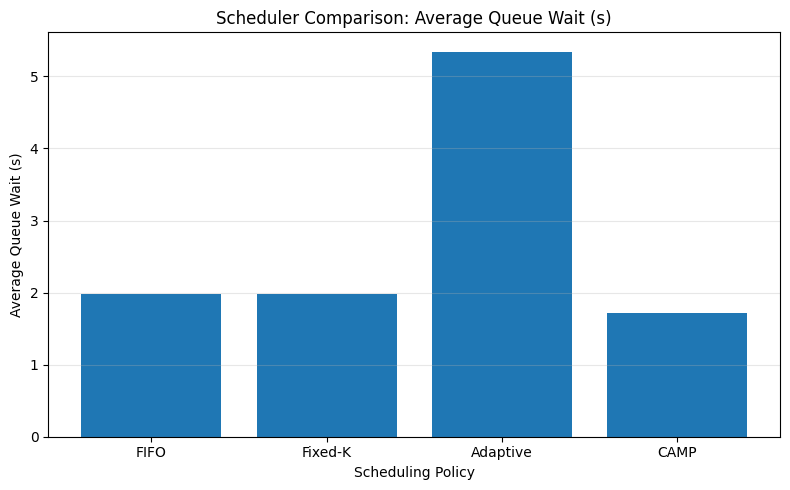

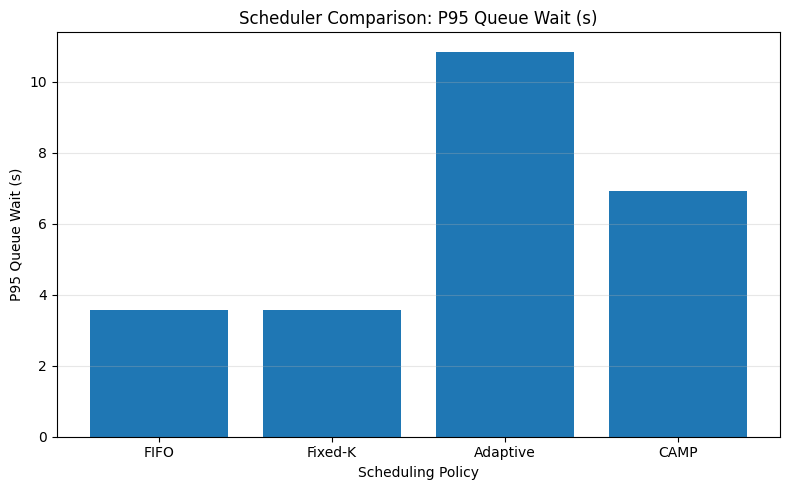

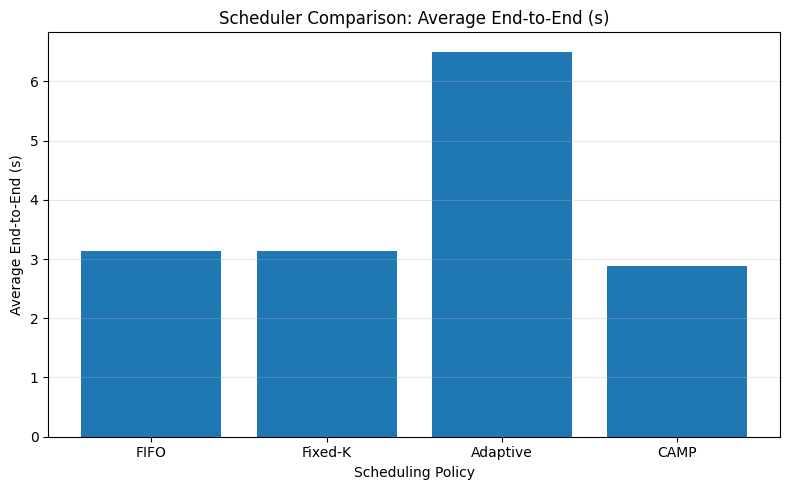

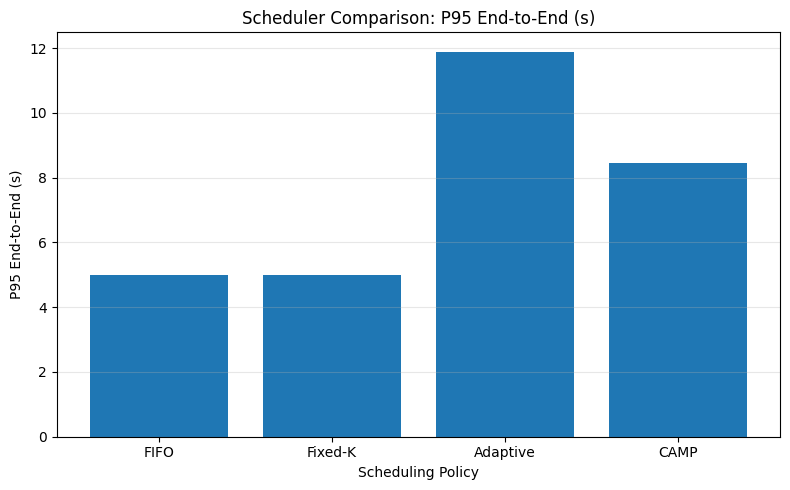

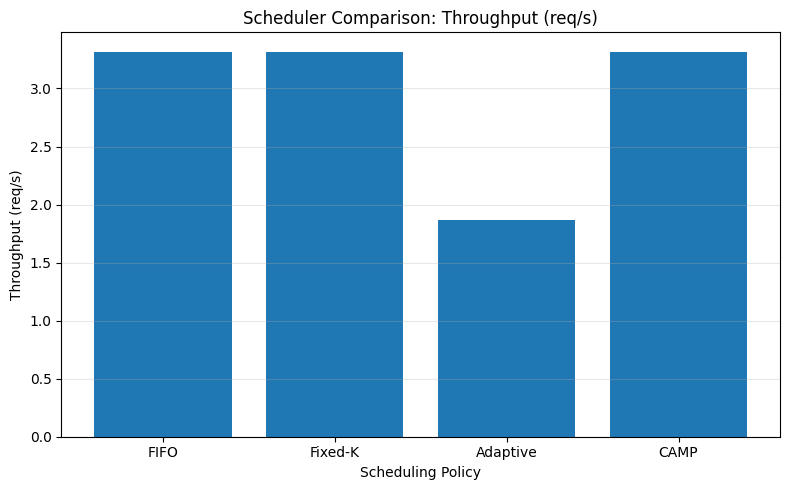

In [51]:

import matplotlib.pyplot as plt
import numpy as np

# Metrics to visualize
metrics = [
    "Average Queue Wait (s)",
    "P95 Queue Wait (s)",
    "Average End-to-End (s)",
    "P95 End-to-End (s)",
    "Throughput (req/s)"
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    plt.bar(
        summary_df["Scheduler"],
        summary_df[metric]
    )

    plt.title(f"Scheduler Comparison: {metric}")
    plt.xlabel("Scheduling Policy")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


In [52]:

# Combine the results from all four schedulers

all_results = []

for policy, result in simulation_results.items():

    temp = result.copy()
    temp["Scheduler"] = policy

    all_results.append(temp)

all_results_df = pd.concat(
    all_results,
    ignore_index=True
)


# Calculate metrics separately for each workload

workload_summary = (
    all_results_df
    .groupby(["workload_type", "Scheduler"])
    .agg(
        Requests=("request_id", "count"),
        Average_Queue_Wait=("queue_wait_s", "mean"),
        P95_Queue_Wait=("queue_wait_s", lambda x: x.quantile(0.95)),
        Average_End_to_End=("end_to_end_s", "mean"),
        P95_End_to_End=("end_to_end_s", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

print("PERFORMANCE BY WORKLOAD TYPE")

display(workload_summary.round(4))


PERFORMANCE BY WORKLOAD TYPE


,workload_type,Scheduler,Requests,Average_Queue_Wait,P95_Queue_Wait,Average_End_to_End,P95_End_to_End
0,bursty,Adaptive,12,5.2100,11.0460,6.4048,12.4981
1,bursty,CAMP,12,1.6560,5.4103,2.8508,6.9035
2,bursty,FIFO,12,1.8954,3.2929,3.0902,4.6530
3,bursty,Fixed-K,12,1.8954,3.2929,3.0902,4.6530
4,mixed,Adaptive,12,4.0122,9.6726,5.1961,11.0598
5,mixed,CAMP,12,1.6950,4.3051,2.8789,5.7497
6,mixed,FIFO,12,1.7244,3.7899,2.9083,5.1757
7,mixed,Fixed-K,12,1.7244,3.7899,2.9083,5.1757
8,steady,Adaptive,12,6.8109,10.9714,7.9066,11.8982
9,steady,CAMP,12,1.8098,7.4285,2.9055,8.9324


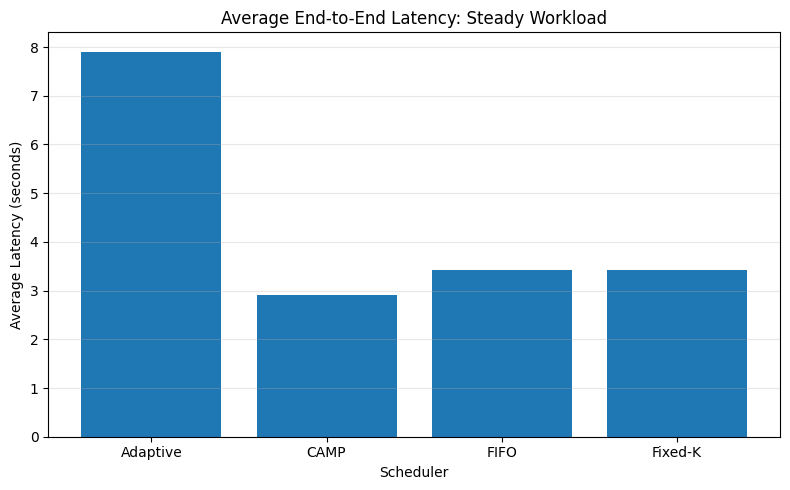

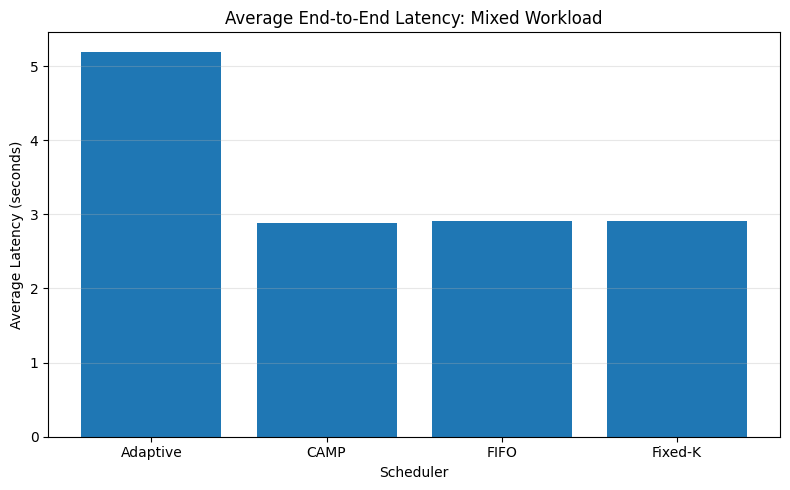

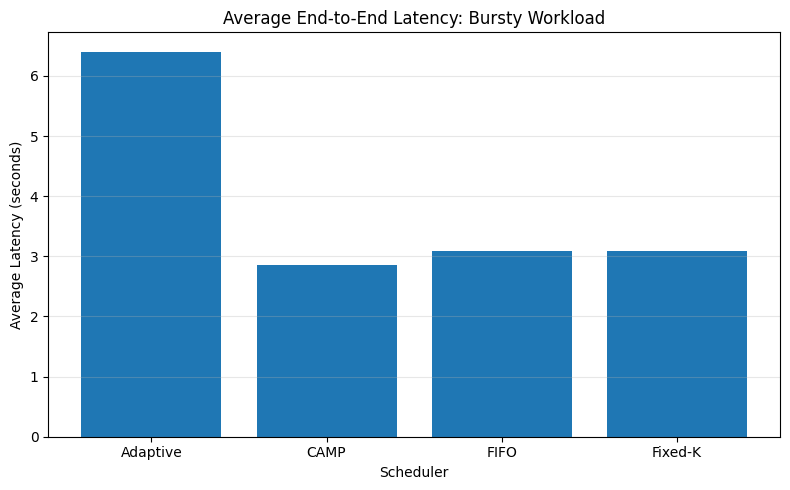

In [53]:

import matplotlib.pyplot as plt

for workload in ["steady", "mixed", "bursty"]:

    subset = workload_summary[
        workload_summary["workload_type"] == workload
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        subset["Scheduler"],
        subset["Average_End_to_End"]
    )

    plt.title(f"Average End-to-End Latency: {workload.title()} Workload")
    plt.xlabel("Scheduler")
    plt.ylabel("Average Latency (seconds)")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


In [54]:

# Save the overall scheduler comparison
summary_df.to_csv(
    "scheduler_overall_comparison.csv",
    index=False
)

# Save workload-specific comparison
workload_summary.to_csv(
    "scheduler_workload_comparison.csv",
    index=False
)

# Save individual request-level results
all_results_df.to_csv(
    "scheduler_request_results.csv",
    index=False
)

print("All scheduler results saved successfully!")

print("\nSaved files:")
print("1. scheduler_overall_comparison.csv")
print("2. scheduler_workload_comparison.csv")
print("3. scheduler_request_results.csv")


All scheduler results saved successfully!

Saved files:
1. scheduler_overall_comparison.csv
2. scheduler_workload_comparison.csv
3. scheduler_request_results.csv


In [55]:

# Create a fair comparison configuration

FAIR_MAX_CONCURRENCY = 4

print("Fair comparison configuration")
print("Maximum concurrency for all schedulers:",
      FAIR_MAX_CONCURRENCY)

print("\nPolicies:")
print("1. FIFO - FIFO queue, concurrency 4")
print("2. Fixed-K - Fixed concurrency 4")
print("3. Adaptive - Dynamic concurrency (2 or 4)")
print("4. CAMP - ML-based predicted service-time priority, concurrency 4")


Fair comparison configuration
Maximum concurrency for all schedulers: 4

Policies:
1. FIFO - FIFO queue, concurrency 4
2. Fixed-K - Fixed concurrency 4
3. Adaptive - Dynamic concurrency (2 or 4)
4. CAMP - ML-based predicted service-time priority, concurrency 4


In [56]:

# Run the fair scheduler comparison

policies = ["FIFO", "Fixed-K", "Adaptive", "CAMP"]

fair_simulation_results = {}

for policy in policies:

    result = simulate_scheduler(simulation_df, policy)

    fair_simulation_results[policy] = result

    print(f"{policy}: {len(result)} requests completed")


fair_summary = []

for policy, result in fair_simulation_results.items():

    makespan = (
        result["completion_time_s"].max()
        - result["arrival_time_s"].min()
    )

    fair_summary.append({
        "Scheduler": policy,
        "Completed Requests": len(result),
        "Average Queue Wait (s)": result["queue_wait_s"].mean(),
        "P95 Queue Wait (s)": result["queue_wait_s"].quantile(0.95),
        "Average End-to-End (s)": result["end_to_end_s"].mean(),
        "P95 End-to-End (s)": result["end_to_end_s"].quantile(0.95),
        "Throughput (req/s)": len(result) / makespan
    })

fair_summary_df = pd.DataFrame(fair_summary)

print("\nFAIR SCHEDULER COMPARISON")
display(fair_summary_df.round(4))


FIFO: 36 requests completed
Fixed-K: 36 requests completed
Adaptive: 36 requests completed
CAMP: 36 requests completed

FAIR SCHEDULER COMPARISON


,Scheduler,Completed Requests,Average Queue Wait (s),P95 Queue Wait (s),Average End-to-End (s),P95 End-to-End (s),Throughput (req/s)
0,FIFO,36,1.9820,3.5751,3.1401,4.9982,3.3179
1,Fixed-K,36,1.9820,3.5751,3.1401,4.9982,3.3179
2,Adaptive,36,5.3444,10.8564,6.5025,11.8957,1.8649
3,CAMP,36,1.7203,6.9367,2.8784,8.4436,3.3132


In [57]:
# Save fair scheduler comparison

fair_summary_df.to_csv(
    "fair_scheduler_comparison.csv",
    index=False
)

# Save request-level results

fair_all_results = []

for policy, result in fair_simulation_results.items():

    temp = result.copy()
    temp["Scheduler"] = policy

    fair_all_results.append(temp)

fair_all_results_df = pd.concat(
    fair_all_results,
    ignore_index=True
)

fair_all_results_df.to_csv(
    "fair_scheduler_request_results.csv",
    index=False
)

print("Fair comparison results saved successfully!")

Fair comparison results saved successfully!


In [58]:

# Analyze request waiting time by predicted service time

camp_results = fair_simulation_results["CAMP"].copy()

# Divide requests into short, medium and long
camp_results["Request_Size"] = pd.qcut(
    camp_results["service_time_s"],
    q=3,
    labels=["Short", "Medium", "Long"]
)

fairness_summary = (
    camp_results
    .groupby("Request_Size", observed=False)
    .agg(
        Request_Count=("request_id", "count"),
        Average_Wait=("queue_wait_s", "mean"),
        Maximum_Wait=("queue_wait_s", "max"),
        Average_Response=("end_to_end_s", "mean")
    )
    .reset_index()
)

print("CAMP REQUEST FAIRNESS ANALYSIS")

display(fairness_summary.round(4))


CAMP REQUEST FAIRNESS ANALYSIS


,Request_Size,Request_Count,Average_Wait,Maximum_Wait,Average_Response
0,Short,12,0.2663,0.7300,1.1101
1,Medium,12,1.1703,2.2638,2.3401
2,Long,12,3.7244,7.5285,5.1851


In [59]:

# Compare all five scheduling policies

policies = [
    "FIFO",
    "Fixed-K",
    "Adaptive",
    "CAMP",
    "Fair-CAMP"
]

fair_camp_results = {}

for policy in policies:

    result = simulate_scheduler(simulation_df, policy)

    fair_camp_results[policy] = result

    print(f"{policy}: {len(result)} requests completed")


# Calculate performance metrics

comparison = []

for policy, result in fair_camp_results.items():

    makespan = (
        result["completion_time_s"].max()
        - result["arrival_time_s"].min()
    )

    comparison.append({
        "Scheduler": policy,
        "Completed Requests": len(result),
        "Average Queue Wait (s)": result["queue_wait_s"].mean(),
        "P95 Queue Wait (s)": result["queue_wait_s"].quantile(0.95),
        "Average End-to-End (s)": result["end_to_end_s"].mean(),
        "P95 End-to-End (s)": result["end_to_end_s"].quantile(0.95),
        "Throughput (req/s)": len(result) / makespan
    })


fair_camp_summary = pd.DataFrame(comparison)

print("\nFIVE-POLICY PERFORMANCE COMPARISON")

display(fair_camp_summary.round(4))


FIFO: 36 requests completed
Fixed-K: 36 requests completed
Adaptive: 36 requests completed
CAMP: 36 requests completed
Fair-CAMP: 36 requests completed

FIVE-POLICY PERFORMANCE COMPARISON


,Scheduler,Completed Requests,Average Queue Wait (s),P95 Queue Wait (s),Average End-to-End (s),P95 End-to-End (s),Throughput (req/s)
0,FIFO,36,1.9820,3.5751,3.1401,4.9982,3.3179
1,Fixed-K,36,1.9820,3.5751,3.1401,4.9982,3.3179
2,Adaptive,36,5.3444,10.8564,6.5025,11.8957,1.8649
3,CAMP,36,1.7203,6.9367,2.8784,8.4436,3.3132
4,Fair-CAMP,36,1.8972,3.6577,3.0553,4.9447,3.3100


In [60]:

# Fair-CAMP request fairness analysis

fair_camp_request_results = fair_camp_results["Fair-CAMP"].copy()

fair_camp_request_results["Request_Size"] = pd.qcut(
    fair_camp_request_results["service_time_s"],
    q=3,
    labels=["Short", "Medium", "Long"]
)

fair_camp_fairness = (
    fair_camp_request_results
    .groupby("Request_Size", observed=False)
    .agg(
        Request_Count=("request_id", "count"),
        Average_Wait=("queue_wait_s", "mean"),
        Maximum_Wait=("queue_wait_s", "max"),
        Average_Response=("end_to_end_s", "mean")
    )
    .reset_index()
)

print("FAIR-CAMP REQUEST FAIRNESS ANALYSIS")

display(fair_camp_fairness.round(4))


FAIR-CAMP REQUEST FAIRNESS ANALYSIS


,Request_Size,Request_Count,Average_Wait,Maximum_Wait,Average_Response
0,Short,12,1.0550,3.7676,1.8988
1,Medium,12,1.9420,3.5360,3.1118
2,Long,12,2.6945,3.7437,4.1552


In [63]:
# Recreate CAMP request fairness analysis

camp_request_results = fair_simulation_results["CAMP"].copy()

camp_request_results["Request_Size"] = pd.qcut(
    camp_request_results["service_time_s"],
    q=3,
    labels=["Short", "Medium", "Long"]
)

camp_fairness = (
    camp_request_results
    .groupby("Request_Size", observed=False)
    .agg(
        Request_Count=("request_id", "count"),
        Average_Wait=("queue_wait_s", "mean"),
        Maximum_Wait=("queue_wait_s", "max"),
        Average_Response=("end_to_end_s", "mean")
    )
    .reset_index()
)

print("CAMP REQUEST FAIRNESS ANALYSIS")
display(camp_fairness.round(4))

CAMP REQUEST FAIRNESS ANALYSIS


,Request_Size,Request_Count,Average_Wait,Maximum_Wait,Average_Response
0,Short,12,0.2663,0.7300,1.1101
1,Medium,12,1.1703,2.2638,2.3401
2,Long,12,3.7244,7.5285,5.1851


In [64]:
# Compare CAMP and Fair-CAMP fairness

camp_compare = camp_fairness.copy()
fair_camp_compare = fair_camp_fairness.copy()

camp_compare = camp_compare.rename(columns={
    "Average_Wait": "CAMP_Average_Wait",
    "Maximum_Wait": "CAMP_Maximum_Wait",
    "Average_Response": "CAMP_Average_Response"
})

fair_camp_compare = fair_camp_compare.rename(columns={
    "Average_Wait": "Fair_CAMP_Average_Wait",
    "Maximum_Wait": "Fair_CAMP_Maximum_Wait",
    "Average_Response": "Fair_CAMP_Average_Response"
})

fairness_comparison = camp_compare.merge(
    fair_camp_compare,
    on="Request_Size"
)

fairness_comparison["Average_Wait_Reduction_Pct"] = (
    (fairness_comparison["CAMP_Average_Wait"] -
     fairness_comparison["Fair_CAMP_Average_Wait"])
    / fairness_comparison["CAMP_Average_Wait"]
) * 100

print("CAMP vs FAIR-CAMP FAIRNESS COMPARISON")
display(fairness_comparison.round(2))

CAMP vs FAIR-CAMP FAIRNESS COMPARISON


,Request_Size,Request_Count_x,CAMP_Average_Wait,CAMP_Maximum_Wait,CAMP_Average_Response,Request_Count_y,Fair_CAMP_Average_Wait,Fair_CAMP_Maximum_Wait,Fair_CAMP_Average_Response,Average_Wait_Reduction_Pct
0,Short,12,0.27,0.73,1.11,12,1.05,3.77,1.90,-296.20
1,Medium,12,1.17,2.26,2.34,12,1.94,3.54,3.11,-65.94
2,Long,12,3.72,7.53,5.19,12,2.69,3.74,4.16,27.65


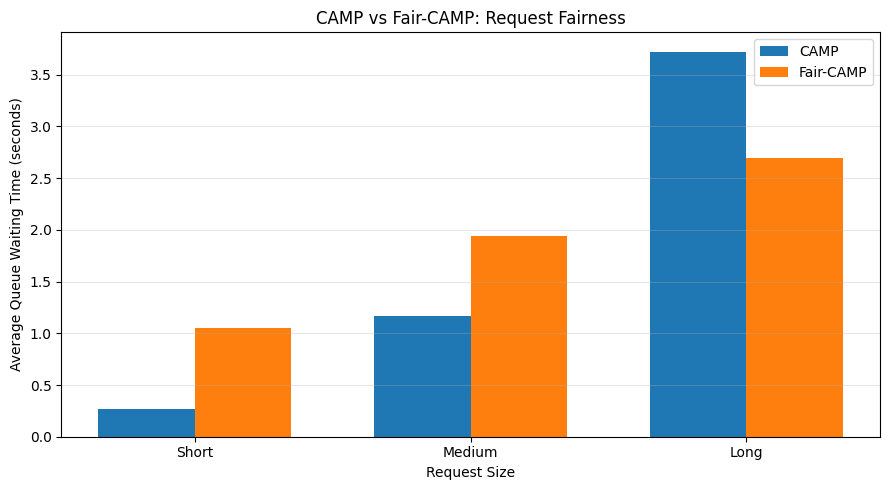

In [65]:
import matplotlib.pyplot as plt
import numpy as np

sizes = ["Short", "Medium", "Long"]

camp_wait = camp_fairness["Average_Wait"].values
fair_camp_wait = fair_camp_fairness["Average_Wait"].values

x = np.arange(len(sizes))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, camp_wait, width, label="CAMP")
plt.bar(x + width/2, fair_camp_wait, width, label="Fair-CAMP")

plt.xlabel("Request Size")
plt.ylabel("Average Queue Waiting Time (seconds)")
plt.title("CAMP vs Fair-CAMP: Request Fairness")
plt.xticks(x, sizes)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# Cell 35: Overall scheduler performance comparison

scheduler_names = fair_comparison_df["Scheduler"].values
avg_wait = fair_comparison_df["Avg_Queue_Wait"].values
avg_response = fair_comparison_df["Avg_End_to_End"].values

x = np.arange(len(scheduler_names))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(x - width/2, avg_wait, width, label="Average Queue Wait")
plt.bar(x + width/2, avg_response, width, label="Average End-to-End Latency")

plt.xlabel("Scheduling Policy")
plt.ylabel("Time (seconds)")
plt.title("Performance Comparison of Scheduling Policies")
plt.xticks(x, scheduler_names, rotation=15)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'fair_comparison_df' is not defined

In [67]:
print("Available columns:")
print(fair_scheduler_comparison.columns.tolist())

print("\nScheduler comparison results:")
display(fair_scheduler_comparison.round(4))

Available columns:


NameError: name 'fair_scheduler_comparison' is not defined

In [68]:
# Check which project variables currently exist

important_variables = [
    "fair_simulation_results",
    "fair_camp_results",
    "fair_scheduler_comparison",
    "fair_scheduler_request_results",
    "benchmark_df",
    "benchmark_traces",
    "predictor",
    "model"
]

for name in important_variables:
    print(name, ":", "AVAILABLE" if name in globals() else "NOT AVAILABLE")

fair_simulation_results : AVAILABLE
fair_camp_results : AVAILABLE
fair_scheduler_comparison : NOT AVAILABLE
fair_scheduler_request_results : NOT AVAILABLE
benchmark_df : AVAILABLE
benchmark_traces : NOT AVAILABLE
predictor : NOT AVAILABLE
model : NOT AVAILABLE


In [69]:
# Rebuild scheduler comparison from existing simulation results

scheduler_names = ["FIFO", "Fixed-K", "Adaptive", "CAMP", "Fair-CAMP"]

comparison_rows = []

for name in scheduler_names:

    if name == "Fair-CAMP":
        results = fair_camp_results[name].copy()
    else:
        results = fair_simulation_results[name].copy()

    comparison_rows.append({
        "Scheduler": name,
        "Completed": len(results),
        "Avg_Queue_Wait": results["queue_wait_s"].mean(),
        "P95_Queue_Wait": results["queue_wait_s"].quantile(0.95),
        "Avg_End_to_End": results["end_to_end_s"].mean(),
        "P95_End_to_End": results["end_to_end_s"].quantile(0.95),
        "Throughput": len(results) / (
            results["completion_time_s"].max()
            - results["arrival_offset_s"].min()
        )
    })

fair_scheduler_comparison = pd.DataFrame(comparison_rows)

print("FINAL FIVE-SCHEDULER COMPARISON")
display(fair_scheduler_comparison.round(4))

KeyError: 'arrival_offset_s'

In [70]:
# Inspect the structure of the existing simulation results

for scheduler in ["FIFO", "Fixed-K", "Adaptive", "CAMP"]:
    print("\n", scheduler)
    print(fair_simulation_results[scheduler].columns.tolist())
    display(fair_simulation_results[scheduler].head(2))

print("\nFair-CAMP")
print(fair_camp_results["Fair-CAMP"].columns.tolist())
display(fair_camp_results["Fair-CAMP"].head(2))


 FIFO
['request_id', 'workload_type', 'arrival_time_s', 'start_time_s', 'service_time_s', 'queue_wait_s', 'completion_time_s', 'end_to_end_s']


,request_id,workload_type,arrival_time_s,start_time_s,service_time_s,queue_wait_s,completion_time_s,end_to_end_s
0,benchmark_bursty_req_0000,bursty,0.0,0.0,1.095871,0.0,1.095871,1.095871
1,benchmark_mixed_req_0000,mixed,0.0,0.0,1.098209,0.0,1.098209,1.098209



 Fixed-K
['request_id', 'workload_type', 'arrival_time_s', 'start_time_s', 'service_time_s', 'queue_wait_s', 'completion_time_s', 'end_to_end_s']


,request_id,workload_type,arrival_time_s,start_time_s,service_time_s,queue_wait_s,completion_time_s,end_to_end_s
0,benchmark_bursty_req_0000,bursty,0.0,0.0,1.095871,0.0,1.095871,1.095871
1,benchmark_mixed_req_0000,mixed,0.0,0.0,1.098209,0.0,1.098209,1.098209



 Adaptive
['request_id', 'workload_type', 'arrival_time_s', 'start_time_s', 'service_time_s', 'queue_wait_s', 'completion_time_s', 'end_to_end_s']


,request_id,workload_type,arrival_time_s,start_time_s,service_time_s,queue_wait_s,completion_time_s,end_to_end_s
0,benchmark_bursty_req_0000,bursty,0.0,0.0,1.095871,0.0,1.095871,1.095871
1,benchmark_mixed_req_0000,mixed,0.0,0.0,1.098209,0.0,1.098209,1.098209



 CAMP
['request_id', 'workload_type', 'arrival_time_s', 'start_time_s', 'service_time_s', 'queue_wait_s', 'completion_time_s', 'end_to_end_s']


,request_id,workload_type,arrival_time_s,start_time_s,service_time_s,queue_wait_s,completion_time_s,end_to_end_s
0,benchmark_steady_req_0000,steady,0.0,0.0,0.626715,0.0,0.626715,0.626715
1,benchmark_bursty_req_0000,bursty,0.0,0.0,1.095871,0.0,1.095871,1.095871



Fair-CAMP
['request_id', 'workload_type', 'arrival_time_s', 'start_time_s', 'service_time_s', 'queue_wait_s', 'completion_time_s', 'end_to_end_s']


,request_id,workload_type,arrival_time_s,start_time_s,service_time_s,queue_wait_s,completion_time_s,end_to_end_s
0,benchmark_steady_req_0000,steady,0.0,0.0,0.626715,0.0,0.626715,0.626715
1,benchmark_bursty_req_0000,bursty,0.0,0.0,1.095871,0.0,1.095871,1.095871


In [71]:
# Rebuild comparison table using the correct column names

scheduler_names = ["FIFO", "Fixed-K", "Adaptive", "CAMP", "Fair-CAMP"]

comparison_rows = []

for name in scheduler_names:

    if name == "Fair-CAMP":
        results = fair_camp_results[name].copy()
    else:
        results = fair_simulation_results[name].copy()

    total_time = (
        results["completion_time_s"].max()
        - results["arrival_time_s"].min()
    )

    comparison_rows.append({
        "Scheduler": name,
        "Completed": len(results),
        "Avg_Queue_Wait": results["queue_wait_s"].mean(),
        "P95_Queue_Wait": results["queue_wait_s"].quantile(0.95),
        "Avg_End_to_End": results["end_to_end_s"].mean(),
        "P95_End_to_End": results["end_to_end_s"].quantile(0.95),
        "Throughput": len(results) / total_time
    })

fair_scheduler_comparison = pd.DataFrame(comparison_rows)

print("FINAL FIVE-SCHEDULER COMPARISON")
display(fair_scheduler_comparison.round(4))

FINAL FIVE-SCHEDULER COMPARISON


,Scheduler,Completed,Avg_Queue_Wait,P95_Queue_Wait,Avg_End_to_End,P95_End_to_End,Throughput
0,FIFO,36,1.9820,3.5751,3.1401,4.9982,3.3179
1,Fixed-K,36,1.9820,3.5751,3.1401,4.9982,3.3179
2,Adaptive,36,5.3444,10.8564,6.5025,11.8957,1.8649
3,CAMP,36,1.7203,6.9367,2.8784,8.4436,3.3132
4,Fair-CAMP,36,1.8972,3.6577,3.0553,4.9447,3.3100


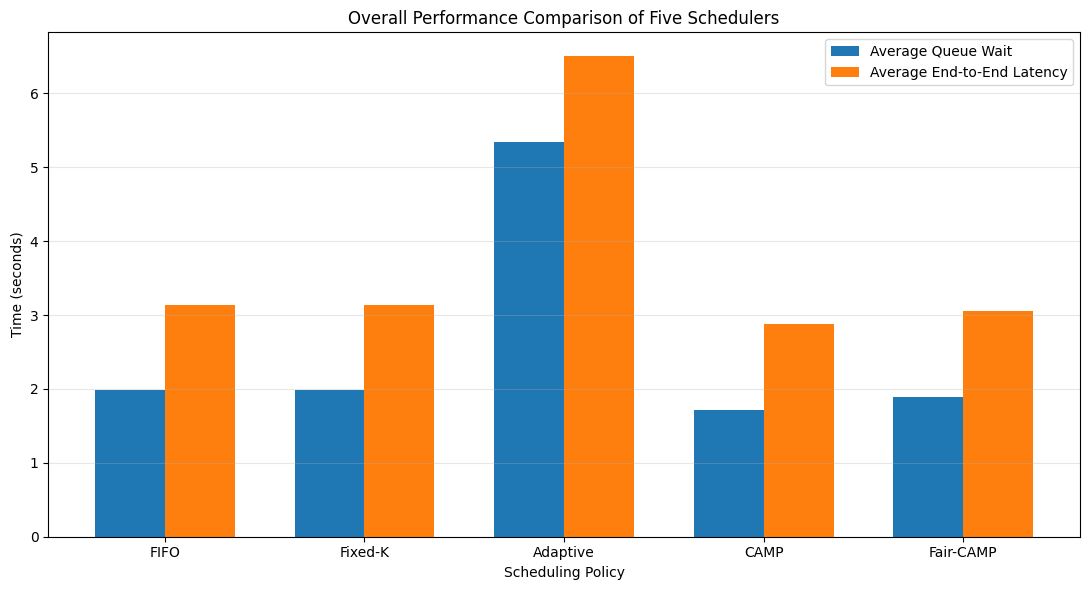

In [72]:
# Cell 37: Overall performance visualization

import matplotlib.pyplot as plt
import numpy as np

df = fair_scheduler_comparison

names = df["Scheduler"]
x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width/2,
    df["Avg_Queue_Wait"],
    width,
    label="Average Queue Wait"
)

ax.bar(
    x + width/2,
    df["Avg_End_to_End"],
    width,
    label="Average End-to-End Latency"
)

ax.set_xlabel("Scheduling Policy")
ax.set_ylabel("Time (seconds)")
ax.set_title("Overall Performance Comparison of Five Schedulers")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [73]:
# Cell 38: Workload-wise scheduler performance

all_results = []

for scheduler in ["FIFO", "Fixed-K", "Adaptive", "CAMP"]:
    results = fair_simulation_results[scheduler].copy()
    results["Scheduler"] = scheduler
    all_results.append(results)

fair_results = fair_camp_results["Fair-CAMP"].copy()
fair_results["Scheduler"] = "Fair-CAMP"
all_results.append(fair_results)

combined_results = pd.concat(all_results, ignore_index=True)

workload_comparison = (
    combined_results
    .groupby(["workload_type", "Scheduler"])
    .agg(
        Average_Wait=("queue_wait_s", "mean"),
        Average_Response=("end_to_end_s", "mean"),
        P95_Wait=("queue_wait_s", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

print("WORKLOAD-WISE SCHEDULER PERFORMANCE")
display(workload_comparison.round(4))

WORKLOAD-WISE SCHEDULER PERFORMANCE


,workload_type,Scheduler,Average_Wait,Average_Response,P95_Wait
0,bursty,Adaptive,5.2100,6.4048,11.0460
1,bursty,CAMP,1.6560,2.8508,5.4103
2,bursty,FIFO,1.8954,3.0902,3.2929
3,bursty,Fair-CAMP,1.7077,2.9025,3.2561
4,bursty,Fixed-K,1.8954,3.0902,3.2929
5,mixed,Adaptive,4.0122,5.1961,9.6726
6,mixed,CAMP,1.6950,2.8789,4.3051
7,mixed,FIFO,1.7244,2.9083,3.7899
8,mixed,Fair-CAMP,1.8136,2.9975,3.6295
9,mixed,Fixed-K,1.7244,2.9083,3.7899


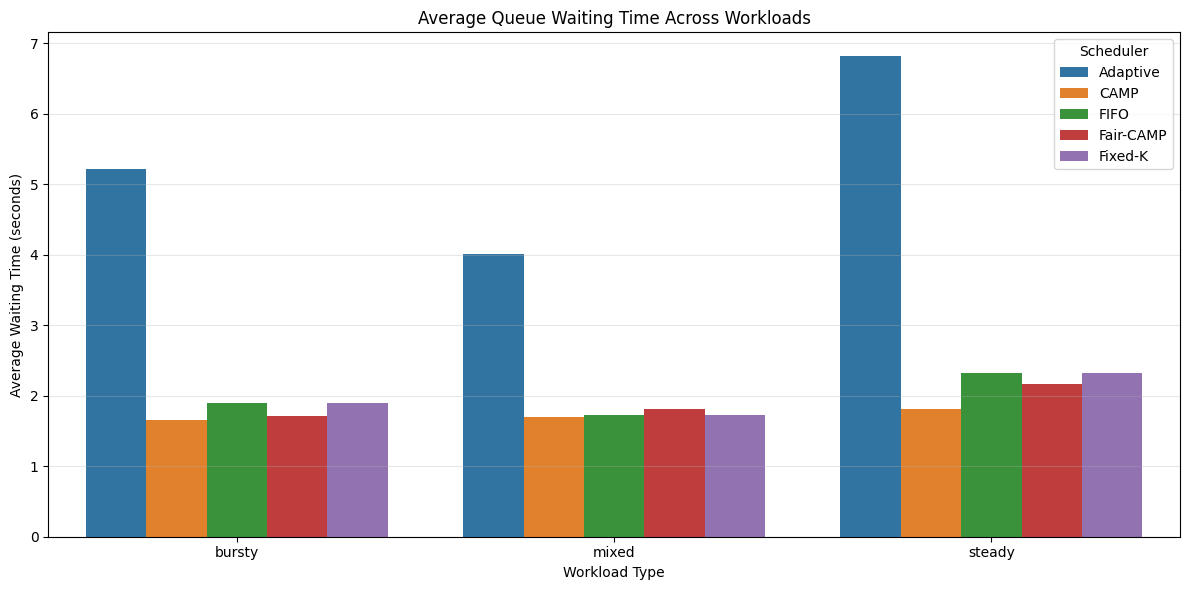

In [75]:
# Cell 39: Workload-wise average waiting time comparison

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=workload_comparison,
    x="workload_type",
    y="Average_Wait",
    hue="Scheduler"
)

plt.title("Average Queue Waiting Time Across Workloads")
plt.xlabel("Workload Type")
plt.ylabel("Average Waiting Time (seconds)")
plt.legend(title="Scheduler")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

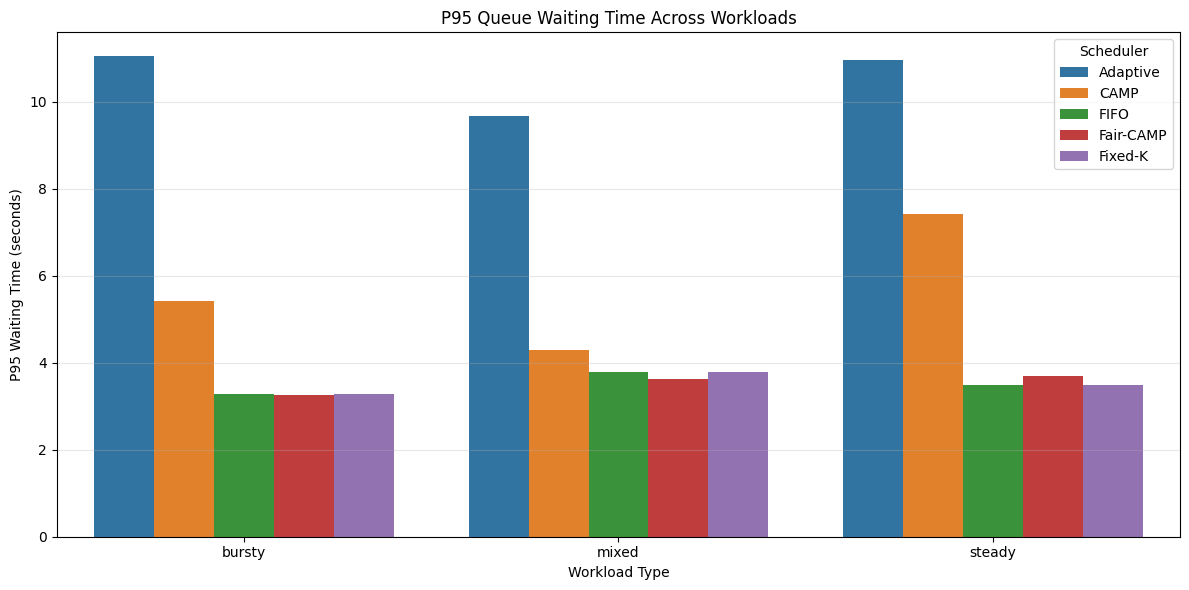

In [76]:
# Cell 40: P95 waiting-time comparison

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=workload_comparison,
    x="workload_type",
    y="P95_Wait",
    hue="Scheduler"
)

plt.title("P95 Queue Waiting Time Across Workloads")
plt.xlabel("Workload Type")
plt.ylabel("P95 Waiting Time (seconds)")
plt.legend(title="Scheduler")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [77]:
# Cell 41: Save final experimental results

# Save overall scheduler comparison
fair_scheduler_comparison.to_csv(
    "final_scheduler_comparison.csv",
    index=False
)

# Save workload-wise comparison
workload_comparison.to_csv(
    "workload_wise_comparison.csv",
    index=False
)

# Save individual request results
combined_results.to_csv(
    "all_scheduler_request_results.csv",
    index=False
)

print("All experimental results saved successfully!")

print("\nFiles created:")
print("1. final_scheduler_comparison.csv")
print("2. workload_wise_comparison.csv")
print("3. all_scheduler_request_results.csv")

All experimental results saved successfully!

Files created:
1. final_scheduler_comparison.csv
2. workload_wise_comparison.csv
3. all_scheduler_request_results.csv


In [78]:
from google.colab import files

files.download("final_scheduler_comparison.csv")
files.download("workload_wise_comparison.csv")
files.download("all_scheduler_request_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [79]:
# Cell 43: Final research findings

baseline = fair_scheduler_comparison[
    fair_scheduler_comparison["Scheduler"] == "FIFO"
].iloc[0]

camp = fair_scheduler_comparison[
    fair_scheduler_comparison["Scheduler"] == "CAMP"
].iloc[0]

fair_camp = fair_scheduler_comparison[
    fair_scheduler_comparison["Scheduler"] == "Fair-CAMP"
].iloc[0]

avg_wait_improvement = (
    (baseline["Avg_Queue_Wait"] - camp["Avg_Queue_Wait"])
    / baseline["Avg_Queue_Wait"]
) * 100

avg_latency_improvement = (
    (baseline["Avg_End_to_End"] - camp["Avg_End_to_End"])
    / baseline["Avg_End_to_End"]
) * 100

tail_wait_improvement = (
    (camp["P95_Queue_Wait"] - fair_camp["P95_Queue_Wait"])
    / camp["P95_Queue_Wait"]
) * 100

print("========== FINAL RESEARCH FINDINGS ==========")

print(f"\nCAMP average waiting-time improvement: {avg_wait_improvement:.2f}%")

print(f"CAMP average latency improvement: {avg_latency_improvement:.2f}%")

print(f"Fair-CAMP P95 waiting-time improvement over CAMP: {tail_wait_improvement:.2f}%")

print("\nCompleted requests:", int(camp["Completed"]))

print("\nCAMP average queue wait:", round(camp["Avg_Queue_Wait"], 4), "seconds")

print("Fair-CAMP P95 queue wait:", round(fair_camp["P95_Queue_Wait"], 4), "seconds")

print("\nAll findings calculated successfully!")

========== FINAL RESEARCH FINDINGS ==========

CAMP average waiting-time improvement: 13.20%
CAMP average latency improvement: 8.33%
Fair-CAMP P95 waiting-time improvement over CAMP: 47.27%

Completed requests: 36

CAMP average queue wait: 1.7203 seconds
Fair-CAMP P95 queue wait: 3.6577 seconds

All findings calculated successfully!


In [80]:
# Cell 44: Save research findings

findings = pd.DataFrame({
    "Research_Metric": [
        "CAMP average waiting-time improvement",
        "CAMP average latency improvement",
        "Fair-CAMP P95 waiting-time improvement",
        "Completed requests"
    ],
    "Value": [
        avg_wait_improvement,
        avg_latency_improvement,
        tail_wait_improvement,
        int(camp["Completed"])
    ]
})

findings.to_csv("final_research_findings.csv", index=False)

display(findings.round(2))

print("Final research findings saved!")

,Research_Metric,Value
0,CAMP average waiting-time improvement,13.20
1,CAMP average latency improvement,8.33
2,Fair-CAMP P95 waiting-time improvement,47.27
3,Completed requests,36.00


Final research findings saved!


In [81]:
# Cell 45: Package all research results

import zipfile
import os

result_files = [
    "final_scheduler_comparison.csv",
    "workload_wise_comparison.csv",
    "all_scheduler_request_results.csv",
    "final_research_findings.csv"
]

with zipfile.ZipFile(
    "CAMP_Final_Research_Results.zip", "w"
) as zip_file:

    for file_name in result_files:
        if os.path.exists(file_name):
            zip_file.write(file_name)

print("Research results packaged successfully!")
print("CAMP_Final_Research_Results.zip")

Research results packaged successfully!
CAMP_Final_Research_Results.zip


In [82]:
from google.colab import files

files.download("CAMP_Final_Research_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>